# Week 5 Task 6: warming patterns per kelvin, JEM slab vs NorESM2



**How the maps were made.**
1. JEM: the mean of the last 10 of 30 years minus the control's 2020–2039 (the same windows as Tasks 3–5), divided by the run's global-mean tas change (1.81 K and 2.51 K). Years 6–30 give the same correlations (section 5).
2. NorESM2: the slopes of the Week 3 pattern-scaling model (6 training scenarios, ensemble means, OLS with intercept; versions A and B share these slopes). Week 3 did not save them, so section 1 recovers them exactly from `results/pattern_scaling_ssp245.nc`.
3. The NorESM2 slopes are regridded conservatively from 96 × 144 to JEM's T31 grid (48 × 96).
4. Internal variability comes from the control's interannual SD. Stippled JEM cells are within 2 standard errors of zero.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

R = "../results/"
FIGS = "../figures/"
DAY = 86400.0
RUNS = ("2xCO2", "4xCO2")

ctl_all = xr.open_dataset(R + "w5-task2_qcontrol_annual.nc").sel(year=slice(2020, 2039))   # baseline, as in Tasks 3-5
ctl = ctl_all.mean("year")
runs_all = {m: xr.open_dataset(R + f"w5-task3_co2x{m[0]}_annual.nc") for m in RUNS}
runs = {m: d.isel(year=slice(-10, None)).mean("year") for m, d in runs_all.items()}  # last 10 of 30 years, as in Tasks 3-5
ps = xr.open_dataset(R + "pattern_scaling_ssp245.nc")                                 # Week 3, version A (oracle T)
for d in runs_all.values():
    assert (d.lat == ctl.lat).all() and (d.lon == ctl.lon).all()

ocean = ctl.ocean_mask == 1
land = ~ocean
w = np.cos(np.deg2rad(ctl.lat))
def gmean(da, mask=None):
    """Area-weighted (cos lat) mean over lat/lon, optionally over a mask."""
    if mask is not None:
        da = da.where(mask)
    return float(da.astype(float).weighted(w).mean(("lat", "lon")))

print("JEM:", dict(ctl_all.sizes), " NorESM2 (Week 3):", dict(ps.sizes))

JEM: {'year': 20, 'lat': 48, 'lon': 96}  NorESM2 (Week 3): {'time': 86, 'lat': 96, 'lon': 144}


## 1. The NorESM2 patterns

Week 3 did not save its patterns, only the `ssp245` predictions $y_\text{cell}(t) = a_\text{cell} + b_\text{cell}\,T(t)$.
The area mean of the tas slope is 1 (Week 3's sanity check), so the area mean of the predicted tas is $c + T(t)$.
Regressing each cell's prediction on that series therefore returns $b_\text{cell}$ exactly, without rerunning Week 3.

In [2]:
wn = np.cos(np.deg2rad(ps.lat))
G = ps.tas.weighted(wn).mean(("lat", "lon")).values.astype(float)   # c + T(t)
X = np.column_stack([np.ones_like(G), G - G.mean()])
nor_native = {}
for v in ("tas", "pr"):                                               # pr is already mm/day in the Week 3 file
    Y = ps[v].values.reshape(len(G), -1).astype(float)
    coef, *_ = np.linalg.lstsq(X, Y, rcond=None)
    print(f"{v}: max |prediction - straight line| = {np.abs(Y - X @ coef).max():.1e} (float32 rounding)")
    nor_native[v] = xr.DataArray(coef[1].reshape(ps.sizes["lat"], ps.sizes["lon"]), dims=("lat", "lon"),
                                 coords={"lat": ps.lat, "lon": ps.lon})
print(f"area mean of the slopes: tas {float(nor_native['tas'].weighted(wn).mean()):.4f} K per K, "
      f"pr {float(nor_native['pr'].weighted(wn).mean()):+.4f} mm/day per K")

tas: max |prediction - straight line| = 3.0e-07 (float32 rounding)
pr: max |prediction - straight line| = 1.3e-07 (float32 rounding)
area mean of the slopes: tas 1.0000 K per K, pr +0.0298 mm/day per K


**Regridding.** NorESM2 is on a 96 × 144 grid, JEM on T31 (48 × 96). The NorESM2 slopes go onto the T31 grid
conservatively: each T31 cell is the area-weighted average of the NorESM2 cells it overlaps. Both grids are separable in
latitude and longitude, so the weights are two small matrices; latitude overlaps are measured in $\sin(\text{lat})$, i.e. in area.

In [3]:
def lat_edges(lat):
    lat = np.asarray(lat)
    return np.concatenate([[-90.0], 0.5 * (lat[1:] + lat[:-1]), [90.0]])

def lon_edges(lon):
    lon = np.asarray(lon)
    d = lon[1] - lon[0]
    return np.concatenate([lon - d / 2, [lon[-1] + d / 2]])

def overlap(src, dst, periodic=False):
    """Fraction of each destination cell covered by each source cell (rows sum to 1)."""
    W = np.zeros((len(dst) - 1, len(src) - 1))
    for shift in ((-360, 0, 360) if periodic else (0,)):
        lo = np.maximum(dst[:-1, None], src[None, :-1] + shift)
        hi = np.minimum(dst[1:, None], src[None, 1:] + shift)
        W += np.clip(hi - lo, 0, None)
    return W / W.sum(1, keepdims=True)

W_lat = overlap(np.sin(np.deg2rad(lat_edges(ps.lat))), np.sin(np.deg2rad(lat_edges(ctl.lat))))
W_lon = overlap(lon_edges(ps.lon), lon_edges(ctl.lon), periodic=True)

def to_t31(da):
    return xr.DataArray(W_lat @ da.values @ W_lon.T, dims=("lat", "lon"), coords={"lat": ctl.lat, "lon": ctl.lon})

nor = {v: to_t31(nor_native[v]) for v in nor_native}
for v in nor:
    print(f"{v} slope, area mean: native grid {float(nor_native[v].weighted(wn).mean()):+.4f}, on T31 {gmean(nor[v]):+.4f}")

tas slope, area mean: native grid +1.0000, on T31 +1.0001
pr slope, area mean: native grid +0.0298, on T31 +0.0298


## 2. The JEM patterns

$\Delta X / \Delta T_\text{global}$ for each run: the mean of the last 10 of 30 years minus the control's 2020–2039, divided by
the run's own global-mean tas change. Internal variability is estimated from the control: a 10-year mean minus a 20-year
mean has a standard error of $\sigma\sqrt{1/10 + 1/20}$ in each cell, where $\sigma$ is the control's interannual SD.

In [4]:
jem, noise = {}, {}
sd = {"tas": ctl_all.tas.std("year", ddof=1), "pr": ctl_all.pr.std("year", ddof=1) * DAY}
P_CTL = gmean(ctl.pr * DAY)
for m, d in runs.items():
    dT = d.tas - ctl.tas
    dTg = gmean(dT)
    dP = (d.pr - ctl.pr) * DAY
    jem[m] = {"tas": dT / dTg, "pr": dP / dTg, "dTg": dTg}
    noise[m] = {v: sd[v] * np.sqrt(1 / 10 + 1 / 20) / dTg for v in sd}   # standard error, per K of global warming
    sig = {v: gmean(abs(jem[m][v]) > 2 * noise[m][v]) for v in sd}
    print(f"{m}: global dT {dTg:.2f} K; global dP {gmean(dP) / dTg:+.3f} mm/day per K "
          f"= {100 * gmean(dP) / P_CTL / dTg:.1f} % per K (control {P_CTL:.2f} mm/day)")
    print(f"        noise per K, median cell: tas {float(noise[m]['tas'].median()):.2f} K, pr {float(noise[m]['pr'].median()):.3f} mm/day;"
          f"  area where |change| > 2 x noise: tas {sig['tas']:.0%}, pr {sig['pr']:.0%}")
print(f"\nNorESM2 (Week 3): global dP {gmean(nor['pr']):+.3f} mm/day per K")

2xCO2: global dT 1.81 K; global dP +0.069 mm/day per K = 2.3 % per K (control 2.97 mm/day)
        noise per K, median cell: tas 0.06 K, pr 0.047 mm/day;  area where |change| > 2 x noise: tas 99%, pr 58%
4xCO2: global dT 2.51 K; global dP +0.026 mm/day per K = 0.9 % per K (control 2.97 mm/day)
        noise per K, median cell: tas 0.04 K, pr 0.034 mm/day;  area where |change| > 2 x noise: tas 98%, pr 78%

NorESM2 (Week 3): global dP +0.030 mm/day per K


## 3. Temperature: $\Delta T / \Delta T_\text{global}$

White is the global-mean rate (1 K per K). Every map averages to 1, so a region that warms too little in one model must be
balanced by a region that warms too much. JEM cells where the change is within 2 standard errors of zero would be
stippled; for temperature there are almost none.

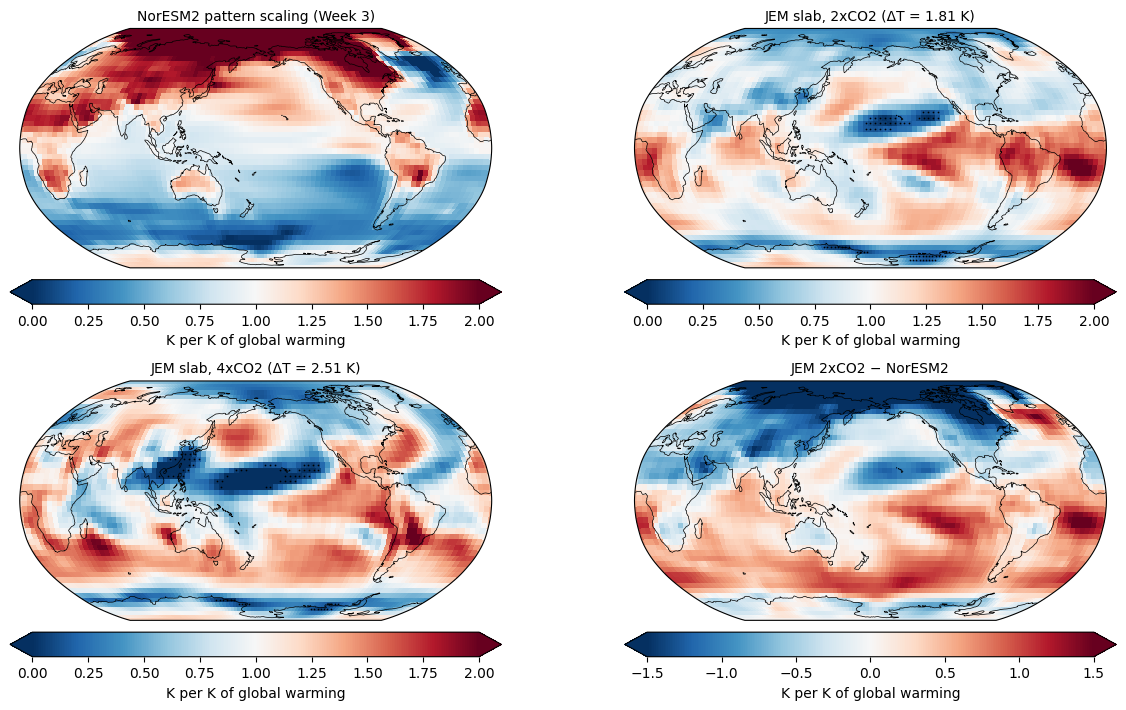

In [5]:
LONE, LATE = lon_edges(ctl.lon), lat_edges(ctl.lat)
LON2, LAT2 = np.meshgrid(ctl.lon.values, ctl.lat.values)

def draw(ax, da, cmap, lo, hi, title, label, insignificant=None):
    m = ax.pcolormesh(LONE, LATE, da.values, transform=ccrs.PlateCarree(), cmap=cmap, vmin=lo, vmax=hi)
    if insignificant is not None:
        s = insignificant.values
        ax.scatter(LON2[s], LAT2[s], s=1.5, c="k", lw=0, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.5)
    ax.set_title(title, fontsize=10)
    plt.colorbar(m, ax=ax, orientation="horizontal", shrink=0.75, pad=0.04, extend="both", label=label)

def four_maps(v, cmap, lo, hi, dlim, unit, fname):
    fig = plt.figure(figsize=(13, 7.2))
    panels = [(nor[v], "NorESM2 pattern scaling (Week 3)", None, (lo, hi)),
              (jem["2xCO2"][v], f"JEM slab, 2xCO2 (ΔT = {jem['2xCO2']['dTg']:.2f} K)", "2xCO2", (lo, hi)),
              (jem["4xCO2"][v], f"JEM slab, 4xCO2 (ΔT = {jem['4xCO2']['dTg']:.2f} K)", "4xCO2", (lo, hi)),
              (jem["2xCO2"][v] - nor[v], "JEM 2xCO2 − NorESM2", None, (-dlim, dlim))]
    for i, (da, title, run, (a, b)) in enumerate(panels):
        ax = fig.add_subplot(2, 2, i + 1, projection=ccrs.Robinson(central_longitude=180))
        insig = (abs(da) < 2 * noise[run][v]) if run else None
        draw(ax, da, cmap, a, b, title, unit, insig)
    fig.tight_layout()
    fig.savefig(FIGS + fname, dpi=150, bbox_inches="tight")
    plt.show()

four_maps("tas", "RdBu_r", 0, 2, 1.5, "K per K of global warming", "week5_task6_dT_maps.png")

In [6]:
def box(da, lat, lon=(0, 360), mask=None):
    """Area-weighted mean over a lat/lon box (lon in 0-360; a box may cross 0E)."""
    if mask is not None:
        da = da.where(mask)
    lo, hi = lon
    inlon = (da.lon >= lo) & (da.lon <= hi) if lo < hi else (da.lon >= lo) | (da.lon <= hi)
    sub = da.where(inlon).sel(lat=slice(*lat))
    return float(sub.weighted(np.cos(np.deg2rad(sub.lat))).mean(("lat", "lon")))

T = {"NorESM2": nor["tas"], "JEM 2xCO2": jem["2xCO2"]["tas"], "JEM 4xCO2": jem["4xCO2"]["tas"]}
t_rows = {
    "land / ocean warming ratio": lambda x: gmean(x, land) / gmean(x, ocean),
    "Arctic, 60-90N": lambda x: box(x, (60, 90)),
    "NH extratropics, 30-60N": lambda x: box(x, (30, 60)),
    "tropics, 30S-30N": lambda x: box(x, (-30, 30)),
    "NH mid-latitude ocean, 30-60N": lambda x: box(x, (30, 60), mask=ocean),
    "SH extratropics, 30-60S": lambda x: box(x, (-60, -30)),
    "Antarctic, 60-90S": lambda x: box(x, (-90, -60)),
    "NH / SH warming ratio": lambda x: box(x, (0, 90)) / box(x, (-90, 0)),
    "subpolar N Atlantic, 45-65N 60-10W": lambda x: box(x, (45, 65), (300, 350)),
    "Southern Ocean, 50-65S": lambda x: box(x, (-65, -50), mask=ocean),
    "east eq. Pacific, 5S-5N 150-90W": lambda x: box(x, (-5, 5), (210, 270)),
    "west eq. Pacific, 5S-5N 130E-180": lambda x: box(x, (-5, 5), (130, 180)),
}
print(f"{'K per K of global warming':36s}" + "".join(f"{k:>11s}" for k in T))
for name, f in t_rows.items():
    print(f"{name:36s}" + "".join(f"{f(x):11.2f}" for x in T.values()))
print("\nJEM surface temperature ts over land, K per K:",
      {m: round(gmean((runs[m].ts - ctl.ts) / jem[m]["dTg"], land), 2) for m in RUNS}, "(air above it: tas)",
      {m: round(gmean(jem[m]["tas"], land), 2) for m in RUNS})
print("NH sea-ice fraction, area mean over 60-90N (land counted as 0):",
      {k: round(box(d.sic.fillna(0), (60, 90)), 3) for k, d in (("control", ctl), *runs.items())})
print("lowest JEM warming per K in any cell:", {m: round(float(jem[m]["tas"].min()), 2) for m in RUNS})

K per K of global warming               NorESM2  JEM 2xCO2  JEM 4xCO2
land / ocean warming ratio                 1.78       0.93       1.03
Arctic, 60-90N                             2.06       0.66       0.70
NH extratropics, 30-60N                    1.35       0.87       1.03
tropics, 30S-30N                           0.98       1.13       0.95
NH mid-latitude ocean, 30-60N              1.10       0.95       1.03
SH extratropics, 30-60S                    0.45       1.06       1.35
Antarctic, 60-90S                          0.60       0.63       0.62
NH / SH warming ratio                      2.02       0.82       0.75
subpolar N Atlantic, 45-65N 60-10W         0.40       1.01       0.88
Southern Ocean, 50-65S                     0.29       0.95       1.02
east eq. Pacific, 5S-5N 150-90W            1.09       1.57       1.48
west eq. Pacific, 5S-5N 130E-180           0.90       0.97       0.65



JEM surface temperature ts over land, K per K: {'2xCO2': 0.19, '4xCO2': 0.21} (air above it: tas) {'2xCO2': 0.95, '4xCO2': 1.02}
NH sea-ice fraction, area mean over 60-90N (land counted as 0): {'control': 0.175, '2xCO2': 0.117, '4xCO2': 0.098}
lowest JEM warming per K in any cell: {'2xCO2': -0.01, '4xCO2': -0.48}


**Temperature.**
- **Agree:** the tropics as a whole warm at about the global rate in both models (0.98 K per K in NorESM2; 1.13 and 0.95 in JEM), and so do the NH mid-latitude oceans (1.10; 0.95 and 1.03). Both warm the east equatorial Pacific faster than the west: 1.09 against 0.90 K per K in NorESM2, 1.57 against 0.97 (2x) and 1.48 against 0.65 (4x) in JEM. JEM has the same El Niño-like shape with a much larger east–west contrast. The 60–90S band warms at about 0.6 K per K in all three.
- **Arctic:** NorESM2 warms 60–90N at 2.06 K per K. JEM warms it at only 0.66 and 0.70, slower than the globe, even though its NH sea ice retreats (60–90N mean fraction 0.175 → 0.117 at 2x, 0.098 at 4x). This is the largest difference on the map.
- **Land:** NorESM2 land warms 1.78 times faster than ocean. In JEM the ratio is 0.93 and 1.03. JEM's land *surface* warms only 0.19–0.21 K per K. The air above it warms 0.95–1.02 K per K, so that heat is carried in from the ocean. This is the land relaxation (`tdland = 1 day`) found in Task 3.
- **Slow-warming oceans:** NorESM2 warms the subpolar North Atlantic at 0.40 and the Southern Ocean at 0.29 K per K. JEM warms both at about 1.0. In a dynamic ocean, these are the regions where the ocean takes heat down: a weakening overturning circulation in the North Atlantic, and upwelling of deep water that has not yet warmed around Antarctica. A Q-flux slab keeps ocean heat transport fixed and has no deep ocean, so it cannot produce either. The NorESM2 pattern also comes from transient runs, where these regions lag most. This difference follows from how the two models are built and is not evidence of a JEM error.
- **Hemispheres:** NorESM2's NH warms 2.02 times as much as its SH. JEM's SH warms more (NH/SH 0.82 and 0.75). The three items above all push the same way, because the NH holds most of the land and the Arctic, and the SH holds the Southern Ocean.
- **Unexplained:** JEM has a patch of weak warming at 10–30N in the western and central Pacific, in both runs and stronger at 4x (one cell cools there, −0.48 K per K). NorESM2 has nothing like it, and we have not diagnosed it. It lies over the region where JEM's rain decreases most (section 4).

## 4. Precipitation: $\Delta P / \Delta T_\text{global}$

Stippled JEM cells: the change is within 2 standard errors of zero (internal variability of the 10-year mean).

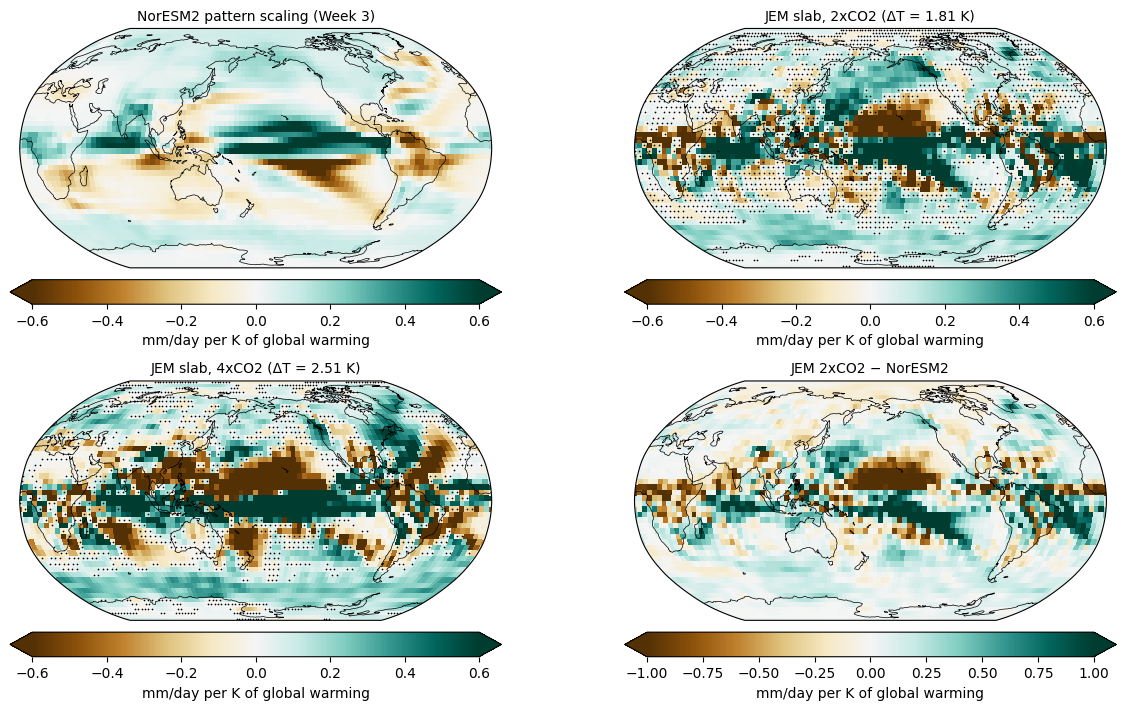

In [7]:
four_maps("pr", "BrBG", -0.6, 0.6, 1.0, "mm/day per K of global warming", "week5_task6_dP_maps.png")

In [8]:
Pm = {"NorESM2": nor["pr"], "JEM 2xCO2": jem["2xCO2"]["pr"], "JEM 4xCO2": jem["4xCO2"]["pr"]}
p_rows = {
    "global": lambda x: gmean(x),
    "over land": lambda x: gmean(x, land),
    "over ocean": lambda x: gmean(x, ocean),
    "0-10N": lambda x: box(x, (0, 10)),
    "10S-0": lambda x: box(x, (-10, 0)),
    "east eq. Pacific, 5S-5N 150-90W": lambda x: box(x, (-5, 5), (210, 270)),
    "Amazon, 15S-5N 70-50W": lambda x: box(x, (-15, 5), (290, 310)),
    "Mediterranean, 30-45N 0-35E": lambda x: box(x, (30, 45), (0, 35)),
    "Southern Ocean, 50-65S": lambda x: box(x, (-65, -50), mask=ocean),
    "Arctic, 60-90N": lambda x: box(x, (60, 90)),
    "spatial RMS about the global mean": lambda x: np.sqrt(gmean((x - gmean(x)) ** 2)),
}
print(f"{'mm/day per K of global warming':36s}" + "".join(f"{k:>11s}" for k in Pm))
for name, f in p_rows.items():
    print(f"{name:36s}" + "".join(f"{f(x):+11.3f}" for x in Pm.values()))

mm/day per K of global warming          NorESM2  JEM 2xCO2  JEM 4xCO2
global                                   +0.030     +0.069     +0.026
over land                                +0.017     -0.045     -0.020
over ocean                               +0.035     +0.115     +0.044
0-10N                                    +0.249     +0.020     -0.095
10S-0                                    -0.027     +0.409     +0.594
east eq. Pacific, 5S-5N 150-90W          +0.414     +0.546     +0.655
Amazon, 15S-5N 70-50W                    -0.304     -0.291     -0.147
Mediterranean, 30-45N 0-35E              -0.068     -0.016     -0.098
Southern Ocean, 50-65S                   +0.072     +0.162     +0.220
Arctic, 60-90N                           +0.084     +0.060     +0.083
spatial RMS about the global mean        +0.212     +0.494     +0.593


**Precipitation.**
- **Global:** 0.069 mm/day per K (2.3% per K) at 2x, 0.026 (0.9% per K) at 4x, and 0.030 in NorESM2. The 4x value is less than half the 2x value. One likely contributor is the fast drop in precipitation from CO2's direct effect on the atmosphere's radiative cooling, which grows with forcing. The Week 4 fixed-SST 2x and 4x runs would measure that fast drop; we have not tested this.
- **Agree:** more rain in the east equatorial Pacific (NorESM2 +0.41; JEM +0.55 and +0.66 mm/day per K), a drier Amazon (−0.30; −0.29 and −0.15), a wetter Southern Ocean storm track (+0.07; +0.16 and +0.22, so the same sign but 2–3 times larger in JEM), and a wetter Arctic (+0.08; +0.06 and +0.08). Poleward of 40°N both get wetter at nearly every latitude, by about 0.05–0.15 mm/day per K; JEM gains more at 45–65°N and NorESM2 more north of 70°N (section 5).
- **The tropical rain band moves the other way.** JEM's control ITCZ peaks at 6–9°N (about 7 mm/day). Under CO2, JEM loses rain at 10–15°N and gains it at 0–10°S (+0.41 and +0.59 mm/day per K). NorESM2 gains rain at 0–10°N (+0.25) and loses it near 10°S. In each model the rain moves toward the hemisphere that warms more, as the atmosphere's cross-equatorial energy transport predicts. So the tropical precipitation disagreement follows from the temperature disagreement. This tropical band carries most of the variance, which is why the overall correlation is about zero.
- **Land:** JEM land gets drier (−0.045 and −0.020 mm/day per K), while NorESM2 land gets wetter (+0.017). One possible cause is that a land surface held near climatology under warmer air gives little extra evaporation. We have not tested this.
- **Amplitude and speckle:** JEM's changes are 2–3 times larger (spatial RMS 0.49 and 0.59 mm/day per K, against 0.21). The NorESM2 slope is a regression over 753 ensemble-mean years, so it is smooth. JEM's tropical changes alternate in sign between neighbouring cells over Africa, South America and the Indian Ocean, so compare regional or zonal means rather than single cells. 42% (2x) and 22% (4x) of the globe is stippled.

## 5. Zonal means and pattern correlations

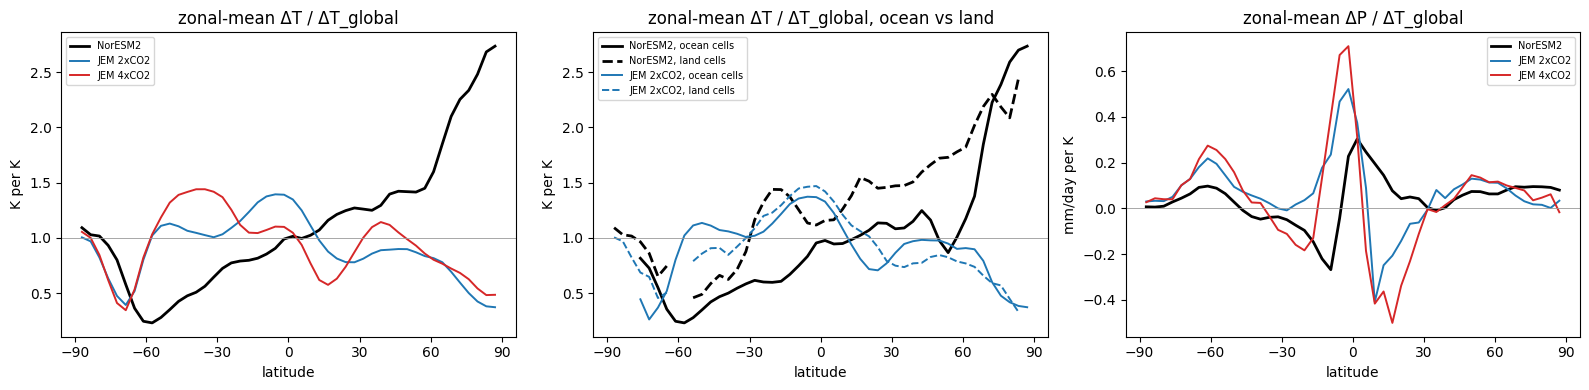

pattern correlation with NorESM2   all cells   ocean    land  |lat|>30  zonal mean
tas, JEM 2xCO2                         -0.27   -0.26   -0.24     -0.45       -0.43
tas, JEM 4xCO2                         -0.16   -0.26   -0.03     -0.29       -0.49
pr, JEM 2xCO2                           0.04    0.03    0.06      0.16       -0.03
pr, JEM 4xCO2                           0.04    0.03    0.10      0.18       -0.04

JEM 2xCO2 vs JEM 4xCO2: tas r = 0.54, pr r = 0.64
  RMS difference: tas 0.39 K per K (noise of the difference about 0.09)
2xCO2, years 6-30: global dT 1.83 K, tas r -0.26, pr r 0.04
4xCO2, years 6-30: global dT 2.52 K, tas r -0.16, pr r 0.04


In [9]:
def corr(a, b, mask=None):
    """Area-weighted, centred pattern correlation (works for maps and for zonal means)."""
    ww = w * xr.ones_like(a)
    if mask is not None:
        ww = ww.where(mask, 0)
    am, bm = (ww * a).sum() / ww.sum(), (ww * b).sum() / ww.sum()
    return float((ww * (a - am) * (b - bm)).sum() / np.sqrt((ww * (a - am) ** 2).sum() * (ww * (b - bm) ** 2).sum()))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
style = {"NorESM2": ("k", 2.0), "JEM 2xCO2": ("C0", 1.4), "JEM 4xCO2": ("C3", 1.4)}
for k, x in T.items():
    axs[0].plot(ctl.lat, x.mean("lon"), color=style[k][0], lw=style[k][1], label=k)
for k in ("NorESM2", "JEM 2xCO2"):
    axs[1].plot(ctl.lat, T[k].where(ocean).mean("lon"), color=style[k][0], lw=style[k][1], label=f"{k}, ocean cells")
    axs[1].plot(ctl.lat, T[k].where(land).mean("lon"), color=style[k][0], lw=style[k][1], ls="--", label=f"{k}, land cells")
for k, x in Pm.items():
    axs[2].plot(ctl.lat, x.mean("lon"), color=style[k][0], lw=style[k][1], label=k)
axs[0].set(title="zonal-mean ΔT / ΔT_global", ylabel="K per K")
axs[1].set(title="zonal-mean ΔT / ΔT_global, ocean vs land", ylabel="K per K")
axs[2].set(title="zonal-mean ΔP / ΔT_global", ylabel="mm/day per K")
for ax, ref in zip(axs, (1, 1, 0)):
    ax.axhline(ref, c="0.6", lw=0.6)
    ax.set_xlabel("latitude")
    ax.set_xticks(range(-90, 91, 30))
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGS + "week5_task6_zonal_means.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'pattern correlation with NorESM2':34s}{'all cells':>10s}{'ocean':>8s}{'land':>8s}{'|lat|>30':>10s}{'zonal mean':>12s}")
extra = xr.ones_like(ocean) & (abs(ctl.lat) > 30)
for v, D in (("tas", T), ("pr", Pm)):
    for k in ("JEM 2xCO2", "JEM 4xCO2"):
        za, zb = D[k].mean("lon"), D["NorESM2"].mean("lon")
        print(f"{v + ', ' + k:34s}{corr(D[k], D['NorESM2']):10.2f}{corr(D[k], D['NorESM2'], ocean):8.2f}"
              f"{corr(D[k], D['NorESM2'], land):8.2f}{corr(D[k], D['NorESM2'], extra):10.2f}{corr(za, zb):12.2f}")
print(f"\nJEM 2xCO2 vs JEM 4xCO2: tas r = {corr(T['JEM 2xCO2'], T['JEM 4xCO2']):.2f}, pr r = {corr(Pm['JEM 2xCO2'], Pm['JEM 4xCO2']):.2f}")
print(f"  RMS difference: tas {np.sqrt(gmean((T['JEM 2xCO2'] - T['JEM 4xCO2']) ** 2)):.2f} K per K "
      f"(noise of the difference about {np.sqrt(gmean(noise['2xCO2']['tas'] ** 2 + noise['4xCO2']['tas'] ** 2)):.2f})")

# Robustness: years 6-30 instead of the last 10
for m in RUNS:
    d = runs_all[m].isel(year=slice(5, None)).mean("year")
    dTg = gmean(d.tas - ctl.tas)
    print(f"{m}, years 6-30: global dT {dTg:.2f} K, tas r {corr((d.tas - ctl.tas) / dTg, nor['tas']):.2f}, "
          f"pr r {corr((d.pr - ctl.pr) * DAY / dTg, nor['pr']):.2f}")

## 6. Answer to Task 6

**Where JEM and NorESM2 agree**
- The tropics warm at about the global rate, and so do the NH mid-latitude oceans.
- The east equatorial Pacific warms faster than the west and gets wetter. The shape is the same, but JEM's east–west contrast is much larger.
- The Amazon gets drier, and the high latitudes and the Southern Ocean storm track get wetter. North of 40°N both get wetter at nearly every latitude.
- At 4x, the global hydrological sensitivity is similar (0.026 against 0.030 mm/day per K).

**Where they do not**
- **Arctic amplification:** 2.06 K per K in NorESM2 against 0.66–0.70 in JEM.
- **Land–sea contrast:** a land/ocean ratio of 1.78 against 0.93–1.03. JEM's land also gets drier instead of wetter.
- **Southern Ocean and subpolar North Atlantic:** both warm slowly in NorESM2 (0.29 and 0.40 K per K), and JEM has no such regions.
- **Interhemispheric contrast and the tropical rain band:** NorESM2's NH warms twice as much as its SH, and its rain moves north. JEM's SH warms more, and its rain moves south.
- **Amplitude:** JEM's precipitation changes are 2–3 times larger and noisier at the grid scale.

**Why, most likely first**
1. **The pinned land (`tdland = 1 day`).** JEM's land surface warms only 0.2 K per K, which removes the land–sea contrast and probably dries the land. It probably also explains much of the missing Arctic amplification, since 60–90N is largely land and the Arctic Ocean is ringed by it, but we have not tested this.
2. **Slab against dynamic ocean, and equilibrium against transient.** The NorESM2 pattern is fit to transient runs, where the Southern Ocean and subpolar North Atlantic lag. A Q-flux slab at equilibrium has no lag and no change in ocean heat transport, so even a perfect slab model would differ here. The NorESM2 pattern also mixes greenhouse-gas and aerosol responses (`historical`, `hist-aer` and the SSPs are in the training set), so it is not a pure CO2 response.
3. **The normalization.** Each map averages to 1 K per K. If JEM's land and Arctic warm too little, its tropics and SH must warm too much. Together with causes 1 and 2, this sets JEM's interhemispheric contrast, which then moves the tropical rain the opposite way from NorESM2.
